# Synthetic Data Generation — Joint Parameter & Noise Tuning (Melcher25 vs NGRIP)

**Goal:** generate synthetic bistable time series with `ClimateCritters`' `Melcher25`
model that look as close as possible to the real NGRIP $\delta^{18}O$ record / DO event
statistics — by jointly tuning **both** the model parameters (`sigma`, `gamma`, `alpha`)
**and** the observation/measurement noise (`sigma_noise`) together, rather than one at a
time.

**Why jointly, and why compare the *noisy* signal to NGRIP:** NGRIP itself is a noisy
proxy measurement, not the "true" internal climate state — so the fair comparison is
between our *noisy synthetic* transitions (detected the same way we'd detect them in a
real noisy record) and the real NGRIP/DO transitions. Tuning parameters and noise
separately can't capture that trade-off; a parameter set that looks great noise-free
might become unusable once realistic measurement error is added, and vice versa.

**Structure**
- Section 1 — NGRIP + DO event ground-truth targets
- Section 2 — Simulation + observation model (model params + noise together)
- Section 3 — Joint random search over (sigma, gamma, alpha, sigma_noise)
- Section 4 — Best configuration vs NGRIP
- Section 5 — Save the chosen synthetic dataset for later analysis (e.g. Ammonyte)


In [17]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import qmc
from scipy.stats import gaussian_kde
import matplotlib.gridspec as gridspec

from climatecritters.model_critters.melcher25 import Melcher25, classify_bistable_states
from climatecritters.utils.noise import from_param

DATA_DIR = "/Users/maryamniati/Documents/Syntheticdata/data"
OUT_DIR  = "/Users/maryamniati/Documents/Syntheticdata"


---
## Section 1 — NGRIP + DO Event Ground-Truth Targets


In [2]:
ngrip = pd.read_csv(f"{DATA_DIR}/NGRIP.csv", skiprows=8, header=None,
                     names=['time', 'd18O', 'extra']).dropna(subset=['time', 'd18O'])
print(f"NGRIP record: {len(ngrip)} points, time range {ngrip.time.min():.2f}-{ngrip.time.max():.2f} kyr b2k")

trans_df = pd.read_csv(f"{DATA_DIR}/DO_events.csv", comment='#')
main_DO = trans_df['main_kyr_b2k'].dropna().sort_values().reset_index(drop=True).values
waiting_times_ngrip = np.diff(main_DO)

NGRIP_TARGETS = dict(
    n_events=len(main_DO),
    mean_waiting=waiting_times_ngrip.mean(),
    median_waiting=np.median(waiting_times_ngrip),
    std_waiting=waiting_times_ngrip.std(),
    cv_waiting=waiting_times_ngrip.std() / waiting_times_ngrip.mean(),
)
print(f"Main DO onsets: {len(main_DO)}")
print("NGRIP targets:", {k: round(v, 3) for k, v in NGRIP_TARGETS.items()})


NGRIP record: 6113 points, time range 0.03-122.27 kyr b2k
Main DO onsets: 25
NGRIP targets: {'n_events': 25, 'mean_waiting': np.float64(4.077), 'median_waiting': np.float64(3.11), 'std_waiting': np.float64(3.453), 'cv_waiting': np.float64(0.847)}


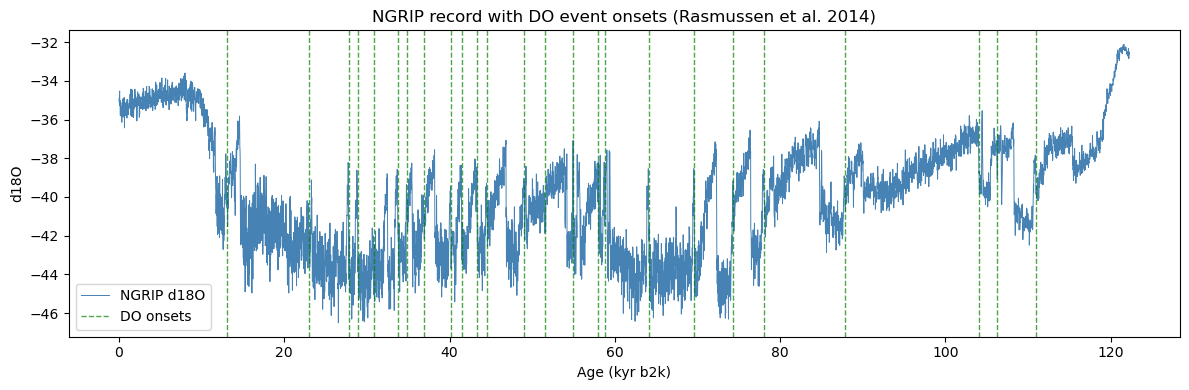

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ngrip.time, ngrip.d18O, lw=0.7, color='steelblue', label='NGRIP d18O')
for i, t in enumerate(main_DO):
    ax.axvline(t, color='green', ls='--', lw=1.0, alpha=0.7, label='DO onsets' if i == 0 else None)
ax.set_xlabel('Age (kyr b2k)'); ax.set_ylabel('d18O')
ax.set_title('NGRIP record with DO event onsets (Rasmussen et al. 2014)')
ax.legend(); plt.tight_layout(); plt.show()


---
## Section 2 — Simulation + Observation Model

`simulate_observed()` runs `Melcher25` for a given (`sigma`, `gamma`, `alpha`), adds
white observation noise (`sigma_noise`) to the `db` state variable via
`climatecritters.utils.noise.from_param` (`method='CN'`, `beta=0` — the white-noise case
of the same colored-noise utility used in `Generate_Data_25events.ipynb`), then
reclassifies stadial/interstadial states from the **noisy** signal via
`classify_bistable_states` — the same post-hoc reclassification the model supports,
applied the way an analyst would apply it to a real noisy proxy record. We keep the
*true* (noise-free) states too, purely for diagnostics.


In [4]:
T_SPAN = (0, 120)   # kyr, matches NGRIP glacial-period coverage (~11-121 ka BP)
DT     = 0.02
Y0     = [1.0, 0.0]

def generate_white_noise(amplitude, length, seed):
    """Zero-mean white (beta=0) observation noise at a target amplitude (std).

    Uses climatecritters.utils.noise.from_param (method='CN', beta=0) — the white-noise
    case of the same colored-noise utility used for the noise-sensitivity study, so both
    notebooks generate observation noise the same way.
    """
    surr = from_param(method='CN', noise_param=[0.0], length=length, number=1, seed=seed)
    raw = np.asarray(surr.series_list[0].value)
    raw = (raw - raw.mean()) / raw.std()
    return amplitude * raw


def simulate_observed(sigma, gamma, alpha, sigma_noise, base_seed, noise_seed):
    model = Melcher25(sigma=sigma, gamma=gamma, alpha=alpha)
    output = model.integrate(t_span=T_SPAN, y0=Y0, method='heun_maruyama', dt=DT,
                              kwargs={'random_seed': base_seed, 'si': DT})

    true_states = np.asarray(output.diagnostic_variables['states']).copy()
    db_true = np.asarray(output.state_variables['db']).copy()

    if sigma_noise > 0:
        noise = generate_white_noise(sigma_noise, length=db_true.shape[0], seed=noise_seed)
        output.add_noise('db', noise)
    db_noisy = np.asarray(output.state_variables['db'])

    observed_states = classify_bistable_states(db_noisy, alpha=alpha)
    return output.time, db_true, db_noisy, true_states, observed_states


def transition_times_from_states(time, states):
    change_idx = np.where(np.diff(states) != 0)[0] + 1
    return time[change_idx]


def waiting_time_stats(trans_times):
    if len(trans_times) < 2:
        return dict(n_events=len(trans_times), mean_waiting=np.nan, median_waiting=np.nan,
                    std_waiting=np.nan, cv_waiting=np.nan)
    wt = np.diff(trans_times)
    return dict(n_events=len(trans_times), mean_waiting=wt.mean(), median_waiting=np.median(wt),
                std_waiting=wt.std(), cv_waiting=wt.std() / wt.mean())


def observed_stats(sigma, gamma, alpha, sigma_noise, base_seed, noise_seed):
    time, db_true, db_noisy, true_states, obs_states = simulate_observed(
        sigma, gamma, alpha, sigma_noise, base_seed, noise_seed)
    return waiting_time_stats(transition_times_from_states(time, obs_states))


---
## Section 3 — Joint Random Search over (sigma, gamma, alpha, sigma_noise)

Random search over all four parameters together (rather than one-at-a-time sweeps),
scored by how close the **observed** (noisy) waiting-time statistics are to the NGRIP
targets. Noise range: `sigma_noise_max = gap_min / 3 ≈ 0.11` (k=3).


In [ ]:
N_TRIALS = 300
N_SEEDS  = 3
rng_search = np.random.default_rng(0)

sigma_range       = (0.25, 0.75)
gamma_range       = (0.8, 3.0)
alpha_range       = (-1.0, 0.0)
sigma_noise_range = (0.0, 0.11)

sampler = qmc.LatinHypercube(d=4, seed=0)
unit_samples = sampler.random(n=N_TRIALS)

l_bounds = [sigma_range[0], gamma_range[0], alpha_range[0], sigma_noise_range[0]]
u_bounds = [sigma_range[1], gamma_range[1], alpha_range[1], sigma_noise_range[1]]
scaled = qmc.scale(unit_samples, l_bounds, u_bounds)

trials = [
    dict(sigma=row[0], gamma=row[1], alpha=row[2], sigma_noise=row[3])
    for row in scaled
]

def evaluate_trial(trial, trial_idx):
    results = [observed_stats(**trial, base_seed=trial_idx * 100 + s, noise_seed=trial_idx * 100 + 500 + s)
               for s in range(N_SEEDS)]
    df_r = pd.DataFrame(results)
    row = dict(trial)
    for col in ['n_events', 'mean_waiting', 'median_waiting', 'std_waiting', 'cv_waiting']:
        row[col] = df_r[col].mean()
    return row

records = Parallel(n_jobs=-1)(
    delayed(evaluate_trial)(t, i) for i, t in enumerate(trials)
)
df_search = pd.DataFrame(records)
print(f"Completed {len(df_search)} trials")


Completed 300 trials


In [6]:
def distance_to_target(row, targets):
    terms = []
    for key in ['n_events', 'mean_waiting', 'median_waiting', 'cv_waiting']:
        if np.isnan(row[key]):
            return np.inf
        terms.append(((row[key] - targets[key]) / targets[key]) ** 2)
    return np.sqrt(np.mean(terms))

df_search['score'] = df_search.apply(lambda r: distance_to_target(r, NGRIP_TARGETS), axis=1)
df_search = df_search.sort_values('score').reset_index(drop=True)

print("Top 10 parameter combinations (closest to NGRIP):")
print(df_search.head(10)[['sigma', 'gamma', 'alpha', 'sigma_noise',
                          'n_events', 'mean_waiting', 'median_waiting', 'cv_waiting', 'score']]
      .to_string(index=False, float_format='{:.3f}'.format))

Top 10 parameter combinations (closest to NGRIP):
 sigma  gamma  alpha  sigma_noise  n_events  mean_waiting  median_waiting  cv_waiting  score
 0.371  1.458 -0.450        0.046    24.667         4.361           2.860       0.862  0.054
 0.334  2.279 -0.770        0.026    26.000         4.670           3.170       0.883  0.079
 0.308  1.162 -0.132        0.085    27.000         4.372           3.617       0.744  0.115
 0.312  1.461 -0.366        0.101    30.667         3.841           2.860       0.896  0.127
 0.362  2.267 -0.952        0.049    31.333         3.868           2.980       0.765  0.140
 0.393  2.009 -0.446        0.035    27.667         4.229           2.477       0.982  0.141
 0.436  1.079 -0.058        0.028    31.667         3.780           3.213       0.734  0.154
 0.379  1.291 -0.361        0.009    24.667         4.916           2.933       1.066  0.168
 0.340  2.346 -0.854        0.096    31.000         3.806           2.773       1.018  0.169
 0.412  1.249 -0.316

In [7]:
BEST = df_search.iloc[0][['sigma', 'gamma', 'alpha', 'sigma_noise']].to_dict()
BEST = {k: float(v) for k, v in BEST.items()}
print('Best joint configuration:', BEST)


Best joint configuration: {'sigma': 0.37123522567804845, 'gamma': 1.4582277114299749, 'alpha': -0.44962706106886396, 'sigma_noise': 0.045750514542913644}


---
## Section 4 — Best Configuration vs NGRIP


In [2]:
time, db_true, db_noisy, true_states, obs_states = simulate_observed(
    BEST['sigma'], BEST['gamma'], BEST['alpha'], BEST['sigma_noise'],
    base_seed=42, noise_seed=2024)

true_transitions = transition_times_from_states(time, true_states)
obs_transitions = transition_times_from_states(time, obs_states)

print('Best config       :', {k: round(v, 3) for k, v in BEST.items()})
print('True stats (no noise, internal state)  :', waiting_time_stats(true_transitions))
print('Observed stats (noisy signal, detected) :', waiting_time_stats(obs_transitions))
print('NGRIP targets                           :', {k: round(v, 3) for k, v in NGRIP_TARGETS.items()})


NameError: name 'simulate_observed' is not defined

In [1]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(time, db_noisy, lw=0.6, color='steelblue', label='Synthetic db (noisy = observed)')
axes[0].plot(time, db_true, lw=0.8, color='darkorange', alpha=0.6, label='Synthetic db (true, no noise)')
for i, t in enumerate(obs_transitions):
    axes[0].axvline(t, color='red', ls='--', lw=0.4, alpha=0.7, label=f'Transitions on observed data (n={len(obs_transitions)})' if i == 0 else None)
axes[0].set_title(f"Best synthetic config: sigma={BEST['sigma']:.3f}, gamma={BEST['gamma']:.3f}, "
                  f"alpha={BEST['alpha']:.3f}, sigma_noise={BEST['sigma_noise']:.3f}")
axes[0].set_xlabel('Time (kyr)'); axes[0].set_ylabel('db'); axes[0].legend(fontsize=8)

wt_obs = np.diff(obs_transitions) if len(obs_transitions) > 1 else np.array([])
axes[1].hist(wt_obs, bins=10, alpha=0.6, color='steelblue', density=True, label='Synthetic (observed)')
axes[1].hist(waiting_times_ngrip, bins=10, alpha=0.6, color='seagreen', density=True, label='NGRIP (DO)')
axes[1].set_xlabel('Waiting time (kyr)'); axes[1].set_ylabel('Density')
axes[1].legend(); axes[1].set_title('Waiting-time distribution: synthetic (observed) vs NGRIP')

plt.tight_layout(); plt.show()


NameError: name 'plt' is not defined

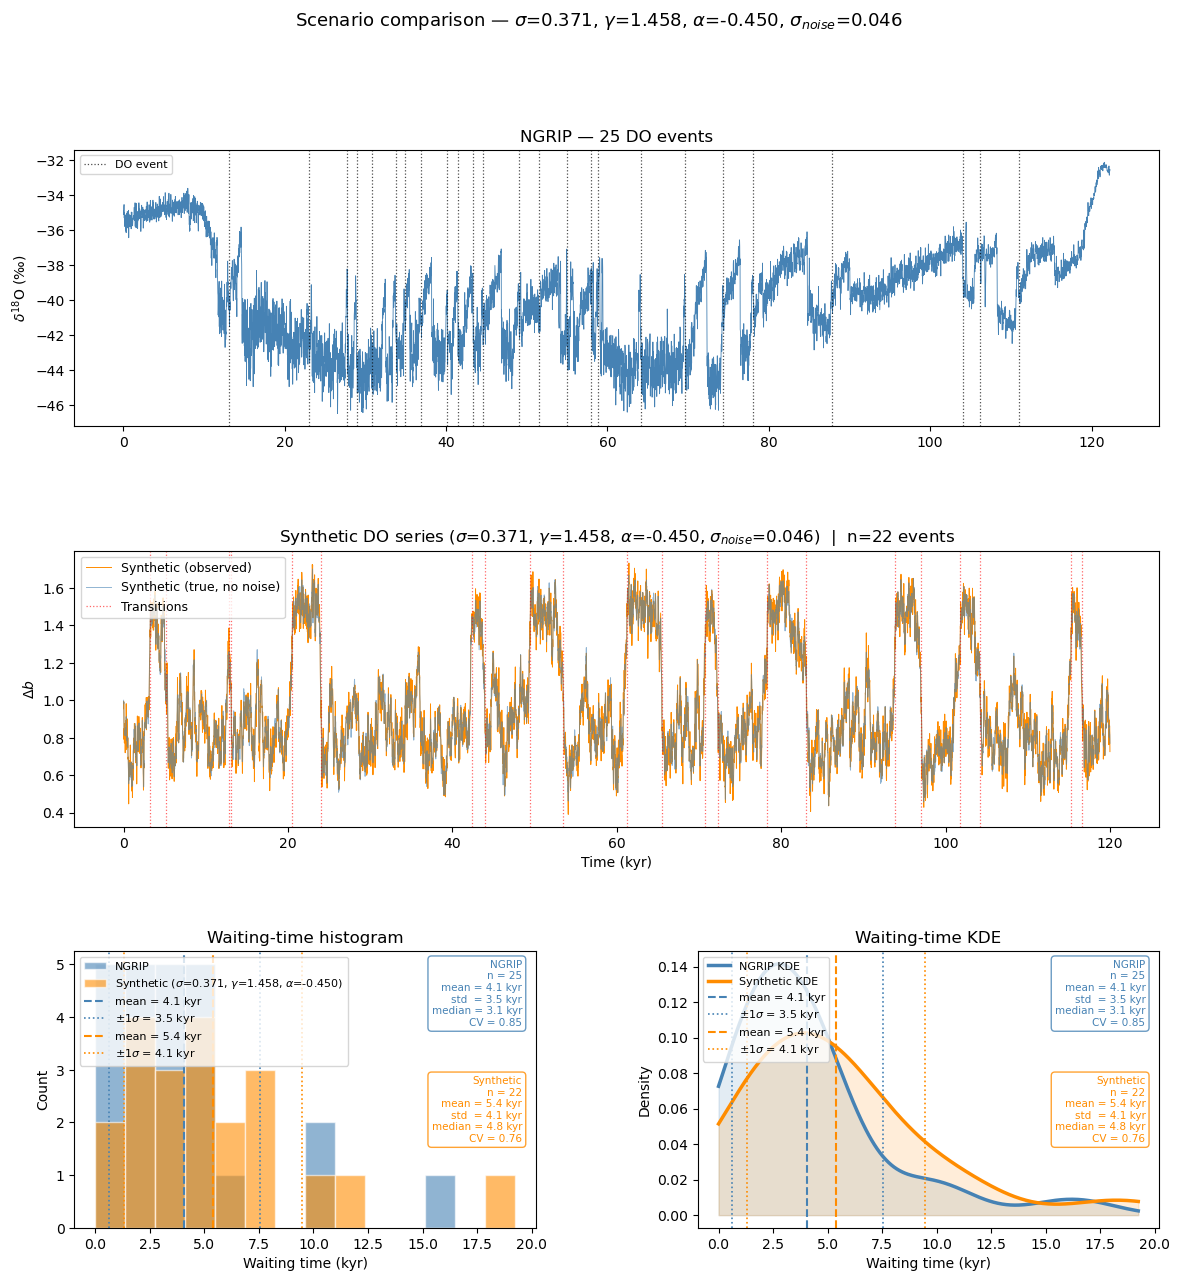

In [20]:
fig = plt.figure(figsize=(14, 14))
gs  = gridspec.GridSpec(3, 2, height_ratios=[1, 1, 1], hspace=0.45, wspace=0.35)

ax_ngrip = fig.add_subplot(gs[0, :])  # NGRIP — full width
ax1      = fig.add_subplot(gs[1, :])  # synthetic — full width
ax2      = fig.add_subplot(gs[2, 0])  # histogram
ax3      = fig.add_subplot(gs[2, 1])  # KDE

# --- Panel 1: NGRIP ---
ax_ngrip.plot(ngrip.time, ngrip.d18O, lw=0.6, color='steelblue')
for i, t in enumerate(main_DO):
    ax_ngrip.axvline(t, color='black', ls=':', lw=0.9, alpha=0.7,
                      label='DO event' if i == 0 else '')
ax_ngrip.set_ylabel(r'$\delta^{18}$O (‰)')
ax_ngrip.set_title(f'NGRIP — {len(main_DO)} DO events')
ax_ngrip.legend(fontsize=8)

# --- Panel 2: synthetic time series (observed = noisy, with true overlaid) ---
ax1.plot(time, db_noisy, lw=0.7, color='darkorange', label='Synthetic (observed)')
ax1.plot(time, db_true, lw=0.7, color='steelblue', alpha=0.6, label='Synthetic (true, no noise)')
for i, t in enumerate(obs_transitions):
    ax1.axvline(t, color='red', lw=0.9, ls=':', alpha=0.6, label='Transitions' if i == 0 else '')
ax1.set_xlabel('Time (kyr)')
ax1.set_ylabel(r'$\Delta b$')
ax1.set_title(
    rf'Synthetic DO series ($\sigma$={BEST["sigma"]:.3f}, $\gamma$={BEST["gamma"]:.3f}, '
    rf'$\alpha$={BEST["alpha"]:.3f}, $\sigma_{{noise}}$={BEST["sigma_noise"]:.3f})  |  '
    rf'n={len(obs_transitions)} events'
)
ax1.legend(fontsize=9)

# --- Shared setup for panels 3 & 4 ---
wt_obs = np.diff(obs_transitions) if len(obs_transitions) > 1 else np.array([])
mean_obs = np.mean(wt_obs) if len(wt_obs) > 0 else np.nan
std_obs  = np.std(wt_obs) if len(wt_obs) > 0 else np.nan

all_wt = np.concatenate([waiting_times_ngrip, wt_obs]) if len(wt_obs) > 0 else waiting_times_ngrip
bins   = np.linspace(0, all_wt.max() * 1.05, 15)
x_grid = np.linspace(0, all_wt.max() * 1.05, 300)

def add_stats_box(ax, waiting, color, y_anchor, label):
    """Write n, mean, std, median, CV as a text box on the axes."""
    mean = np.mean(waiting)
    std  = np.std(waiting)
    cv   = std / mean if mean > 0 else np.nan
    txt  = (f'{label}\n'
            f'n = {len(waiting)+1}\n'
            f'mean = {mean:.1f} kyr\n'
            f'std  = {std:.1f} kyr\n'
            f'median = {np.median(waiting):.1f} kyr\n'
            f'CV = {cv:.2f}')
    ax.text(0.97, y_anchor, txt, transform=ax.transAxes,
            fontsize=7.5, va='top', ha='right', color=color,
            bbox=dict(boxstyle='round,pad=0.35', fc='white', alpha=0.8, ec=color))

def add_mean_std_lines(ax, mean, std, color):
    ax.axvline(mean,       color=color, ls='--', lw=1.5, label=f'mean = {mean:.1f} kyr')
    ax.axvline(mean + std, color=color, ls=':',  lw=1.2)
    ax.axvline(mean - std, color=color, ls=':',  lw=1.2, label=rf'$\pm1\sigma$ = {std:.1f} kyr')

# --- Panel 3: histogram ---
ax2.hist(waiting_times_ngrip, bins=bins, color='steelblue', edgecolor='white',
         alpha=0.6, label='NGRIP')
if len(wt_obs) > 0:
    ax2.hist(wt_obs, bins=bins, color='darkorange', edgecolor='white', alpha=0.6,
             label=rf'Synthetic ($\sigma$={BEST["sigma"]:.3f}, $\gamma$={BEST["gamma"]:.3f}, $\alpha$={BEST["alpha"]:.3f})')

add_mean_std_lines(ax2, NGRIP_TARGETS['mean_waiting'], NGRIP_TARGETS['std_waiting'], 'steelblue')
if not np.isnan(mean_obs):
    add_mean_std_lines(ax2, mean_obs, std_obs, 'darkorange')

add_stats_box(ax2, waiting_times_ngrip, 'steelblue', y_anchor=0.97, label='NGRIP')
if len(wt_obs) > 1:
    add_stats_box(ax2, wt_obs, 'darkorange', y_anchor=0.55, label='Synthetic')

ax2.set_xlabel('Waiting time (kyr)')
ax2.set_ylabel('Count')
ax2.set_title('Waiting-time histogram')
ax2.legend(fontsize=8, loc='upper left')

# --- Panel 4: KDE ---
kde_ngrip = gaussian_kde(waiting_times_ngrip, bw_method='scott')
ax3.plot(x_grid, kde_ngrip(x_grid), color='steelblue', lw=2.5, label='NGRIP KDE')
ax3.fill_between(x_grid, kde_ngrip(x_grid), alpha=0.15, color='steelblue')

if len(wt_obs) > 1:
    kde_obs = gaussian_kde(wt_obs, bw_method='scott')
    ax3.plot(x_grid, kde_obs(x_grid), color='darkorange', lw=2.5, label='Synthetic KDE')
    ax3.fill_between(x_grid, kde_obs(x_grid), alpha=0.15, color='darkorange')

add_mean_std_lines(ax3, NGRIP_TARGETS['mean_waiting'], NGRIP_TARGETS['std_waiting'], 'steelblue')
if not np.isnan(mean_obs):
    add_mean_std_lines(ax3, mean_obs, std_obs, 'darkorange')

add_stats_box(ax3, waiting_times_ngrip, 'steelblue', y_anchor=0.97, label='NGRIP')
if len(wt_obs) > 1:
    add_stats_box(ax3, wt_obs, 'darkorange', y_anchor=0.55, label='Synthetic')

ax3.set_xlabel('Waiting time (kyr)')
ax3.set_ylabel('Density')
ax3.set_title('Waiting-time KDE')
ax3.legend(fontsize=8, loc='upper left')

plt.suptitle(
    rf'Scenario comparison — $\sigma$={BEST["sigma"]:.3f}, $\gamma$={BEST["gamma"]:.3f}, '
    rf'$\alpha$={BEST["alpha"]:.3f}, $\sigma_{{noise}}$={BEST["sigma_noise"]:.3f}',
    fontsize=13
)
plt.show()

### 4.1 Sensitivity around the best configuration

Quick sanity check: how much do the joint-search results vary across the top few
configurations? If they cluster tightly, the fit is well constrained; if they're spread
out, several different parameter/noise combinations produce similarly NGRIP-like
statistics (parameter degeneracy) and any one of them is a defensible choice.


In [10]:
print(df_search.head(15)[['sigma', 'gamma', 'alpha', 'sigma_noise', 'score']]
      .describe().loc[['mean', 'std', 'min', 'max']]
      .to_string(float_format='{:.3f}'.format))


      sigma  gamma  alpha  sigma_noise  score
mean  0.359  1.714 -0.507        0.058  0.155
std   0.054  0.458  0.268        0.032  0.046
min   0.262  1.079 -0.952        0.009  0.054
max   0.472  2.346 -0.058        0.101  0.207


---
## Section 5 — Save the Chosen Synthetic Dataset

Saves the winning configuration plus one labeled example dataset (true `db`, noisy
`db`, true states, observed states, and the known true transition times) — the ground
truth a later notebook can use to evaluate detection methods (e.g. Ammonyte) against.


In [11]:
import os
os.makedirs(OUT_DIR, exist_ok=True)

with open(f"{OUT_DIR}/best_config.json", "w") as f:
    json.dump({**BEST, 't_span': T_SPAN, 'dt': DT, 'y0': Y0}, f, indent=2)

example_df = pd.DataFrame({
    'time': time,
    'db_true': db_true,
    'db_noisy': db_noisy,
    'state_true': true_states,
    'state_observed': obs_states,
})
example_df.to_csv(f"{OUT_DIR}/example_synthetic_dataset.csv", index=False)
np.save(f"{OUT_DIR}/true_transition_times.npy", true_transitions)
np.save(f"{OUT_DIR}/observed_transition_times.npy", obs_transitions)

print(f"Saved best config to {OUT_DIR}/best_config.json")
print(f"Saved example dataset to {OUT_DIR}/example_synthetic_dataset.csv ({len(example_df)} rows)")
print(f"Saved {len(true_transitions)} true / {len(obs_transitions)} observed transition times")


Saved best config to /Users/maryamniati/Documents/Syntheticdata/best_config.json
Saved example dataset to /Users/maryamniati/Documents/Syntheticdata/example_synthetic_dataset.csv (6001 rows)
Saved 20 true / 22 observed transition times
